Project Python Predictive Analytics - 2026-11-07 - Eribek9068

In [10]:
import pandas as pd
from datetime import datetime
from IPython.display import display, Markdown

file_path = r'C:\Files\Excel\Project\Happiness_Development_Index.xlsx'

hdi_df = pd.read_excel(file_path)

student_id = "Eribek9068"
todays_date = datetime.now().strftime("%Y-%m-%d")

display(Markdown(
    f"### Step 1: Load and Explore the Dataset - {student_id} - {todays_date}"
))

display(Markdown("#### First Five Records"))
display(hdi_df.head())

display(Markdown("#### Dataset Information"))
print(hdi_df.info())

### Step 1: Load and Explore the Dataset - Eribek9068 - 2026-11-07

#### First Five Records

,HDI Rank,Country,Human Development Index (HDI),Life expectancy at birth,Expected years of schooling,Mean years of schooling,Gross national income (GNI) per capita
0,1,Switzerland,0.962,83.9872,16.500299,13.85966,66933.00454
1,2,Norway,0.961,83.2339,18.185200,13.00363,64660.10622
2,3,Iceland,0.959,82.6782,19.163059,13.76717,55782.04981
3,4,"Hong Kong, China (SAR)",0.952,85.4734,17.278170,12.22621,62606.84540
4,5,Australia,0.951,84.5265,21.054590,12.72682,49238.43335


#### Dataset Information

<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   HDI Rank                                190 non-null    int64  
 1   Country                                 190 non-null    str    
 2   Human Development Index (HDI)           190 non-null    float64
 3   Life expectancy at birth                190 non-null    float64
 4   Expected years of schooling             190 non-null    float64
 5   Mean years of schooling                 190 non-null    float64
 6   Gross national income (GNI) per capita  190 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 10.5 KB
None


In [11]:
display(Markdown(
    f"### Step 2: One-Hot Encoding - {student_id} - {todays_date}"
))

hdi_encoded = pd.get_dummies(
    hdi_df,
    columns=['Country'],
    drop_first=True
)

display(Markdown("#### Encoded Dataset"))
display(hdi_encoded.head())

### Step 2: One-Hot Encoding - Eribek9068 - 2026-11-07

#### Encoded Dataset

,HDI Rank,Human Development Index (HDI),Life expectancy at birth,Expected years of schooling,Mean years of schooling,Gross national income (GNI) per capita,Country_Albania,Country_Algeria,Country_Andorra,Country_Angola,...,Country_United Kingdom,Country_United States,Country_Uruguay,Country_Uzbekistan,Country_Vanuatu,Country_Venezuela (Bolivarian Republic of),Country_Viet Nam,Country_Yemen,Country_Zambia,Country_Zimbabwe
0,1,0.962,83.9872,16.500299,13.85966,66933.00454,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,0.961,83.2339,18.185200,13.00363,64660.10622,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,0.959,82.6782,19.163059,13.76717,55782.04981,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,0.952,85.4734,17.278170,12.22621,62606.84540,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,0.951,84.5265,21.054590,12.72682,49238.43335,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [17]:
from sklearn.model_selection import train_test_split

display(Markdown(
    f"### Step 3: Split Dataset into Training and Testing Sets - {student_id} - {todays_date}"
))

# Display column names
for col in hdi_df.columns:
    print(col)

# Features
X = hdi_df[
    [
        'Life expectancy at birth',
        'Expected years of schooling',
        'Mean years of schooling',
        'Gross national income (GNI) per capita'
    ]
]

# Target variable
# REPLACE THIS WITH THE ACTUAL HDI COLUMN NAME FROM THE LIST ABOVE
y = hdi_df.iloc[:, 1]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

display(Markdown("#### Training and Testing Set Sizes"))

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

### Step 3: Split Dataset into Training and Testing Sets - Eribek9068 - 2026-11-07

HDI Rank
Country
Human Development Index (HDI) 
Life expectancy at birth
Expected years of schooling
Mean years of schooling
Gross national income (GNI) per capita


#### Training and Testing Set Sizes

Training Records: 133
Testing Records: 57


In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(
    X_train,
    y_train
)

display(Markdown(
    f"### Step 4: Train the Linear Regression Model - {student_id} - {todays_date}"
))

display(Markdown(
    "#### Model Training Complete"
))

### Step 4: Train the Linear Regression Model - Eribek9068 - 2026-11-07

#### Model Training Complete

In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

mse = mean_squared_error(
    y_test,
    predictions
)

r2 = r2_score(
    y_test,
    predictions
)

display(Markdown(
    f"### Step 5: Evaluate the Model - {student_id} - {todays_date}"
))

display(Markdown(
    f"#### Mean Absolute Error (MAE): {mae:.6f}"
))

display(Markdown(
    f"#### Mean Squared Error (MSE): {mse:.6f}"
))

display(Markdown(
    f"#### R-Squared (R²): {r2:.6f}"
))

### Step 5: Evaluate the Model - Eribek9068 - 2026-11-07

#### Mean Absolute Error (MAE): 0.016027

#### Mean Squared Error (MSE): 0.000565

#### R-Squared (R²): 0.970315

In [15]:
feature_importance = pd.DataFrame({

    'Feature': X.columns,
    'Coefficient': model.coef_

})

feature_importance['Absolute Coefficient'] = abs(
    feature_importance['Coefficient']
)

feature_importance = feature_importance.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

display(Markdown(
    f"### Step 6: Feature Importance Analysis - {student_id} - {todays_date}"
))

display(Markdown(
    "#### Feature Importance Ranking"
))

display(feature_importance)

### Step 6: Feature Importance Analysis - Eribek9068 - 2026-11-07

#### Feature Importance Ranking

,Feature,Coefficient,Absolute Coefficient
2,Mean years of schooling,0.017782,0.017782
1,Expected years of schooling,0.012361,0.012361
0,Life expectancy at birth,0.005868,0.005868
3,Gross national income (GNI) per capita,0.000001,0.000001


### Step 7: Plot Feature Importance - Eribek9068 - 2026-11-07

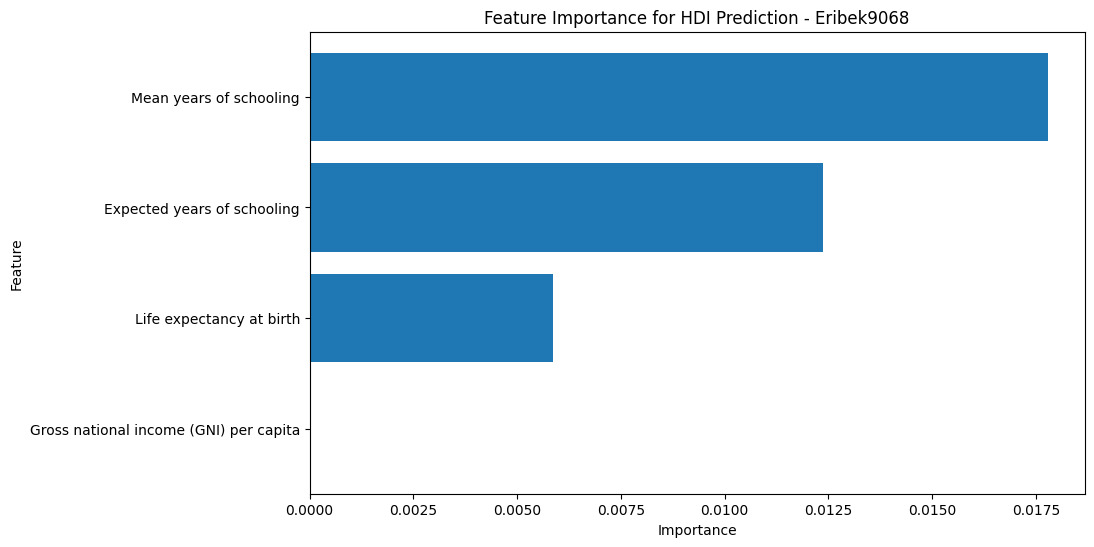

In [16]:
import matplotlib.pyplot as plt

display(Markdown(
    f"### Step 7: Plot Feature Importance - {student_id} - {todays_date}"
))

plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Absolute Coefficient']
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    f"Feature Importance for HDI Prediction - {student_id}"
)

plt.gca().invert_yaxis()

plt.show()

### Step 8: Actionable Features for Prescriptive Policy Analysis - Eribek9068 - 2026-11-08

Based on our feature importance ranking, the three most actionable predictors for national policy interventions are:

1. **Mean years of schooling:** As the highest-weighted linear predictor, adult educational attainment can be directly increased through national literacy initiatives, adult continuing education programs, and vocational training subsidies.
2. **Expected years of schooling:** Governments can directly influence the projected duration of schooling for children entering the education system by mandating compulsory secondary education, eliminating school fees, and funding rural school infrastructure.
3. **Life expectancy at birth:** National healthcare policies—such as universal primary care access, vaccination programs, maternal health initiatives, and clean water sanitation projects—can measurably increase population longevity over time.

While **Gross national income (GNI) per capita** is also a positive factor, macroeconomic growth is harder to mandate directly compared to targeted social, educational, and public health reforms.


In [3]:
import pandas as pd
from datetime import datetime
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Initialize student metadata and load the dataset directly
student_id = "Eribek9068"
todays_date = datetime.now().strftime("%Y-%m-%d")
file_path = r'C:\Files\Excel\Project\Happiness_Development_Index.xlsx'
hdi_df = pd.read_excel(file_path)

display(Markdown(
    f"### Step 9: Simulate Policy Interventions (Below-Median HDI Countries) - {student_id} - {todays_date}"
))

# Automatically find the exact HDI column name (handles with or without trailing space)
hdi_col = [col for col in hdi_df.columns if 'Human Development Index' in col][0]

# Define features and target cleanly
features_list = [
    'Life expectancy at birth',
    'Expected years of schooling',
    'Mean years of schooling',
    'Gross national income (GNI) per capita'
]

X = hdi_df[features_list]
y_fixed = hdi_df[hdi_col]

# Re-split and fit the Linear Regression model cleanly
X_train, X_test, y_train, y_test = train_test_split(X, y_fixed, test_size=0.30, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

# Calculate the median HDI threshold and filter for countries below the median
median_hdi = hdi_df[hdi_col].median()
intervention_df = hdi_df[hdi_df[hdi_col] < median_hdi].copy()

# Record baseline predicted HDI before intervention
intervention_df['Baseline Predicted HDI'] = model.predict(intervention_df[features_list])

# Apply simulated policy interventions (+5% Life Expectancy, +1.5 years Mean Schooling)
X_intervened = intervention_df[features_list].copy()
X_intervened['Life expectancy at birth'] = X_intervened['Life expectancy at birth'] * 1.05
X_intervened['Mean years of schooling'] = X_intervened['Mean years of schooling'] + 1.5

# Predict new HDI values after intervention
intervention_df['Predicted HDI after intervention'] = model.predict(X_intervened)

# Calculate the net projected gain
intervention_df['HDI Gain'] = (
    intervention_df['Predicted HDI after intervention'] - intervention_df[hdi_col]
)

display(Markdown(f"#### Median HDI Threshold: {median_hdi:.4f} | Subset Count: {len(intervention_df)} Countries"))
display(
    intervention_df[
        ['Country', hdi_col, 'Predicted HDI after intervention', 'HDI Gain']
    ].head(10)
)


### Step 9: Simulate Policy Interventions (Below-Median HDI Countries) - Eribek9068 - 2026-11-08

#### Median HDI Threshold: 0.7395 | Subset Count: 95 Countries

,Country,Human Development Index (HDI),Predicted HDI after intervention,HDI Gain
95,Mongolia,0.739,0.780148,0.041148
96,Egypt,0.731,0.764912,0.033912
97,Tunisia,0.731,0.767018,0.036018
98,Fiji,0.730,0.779174,0.049174
99,Suriname,0.730,0.760832,0.030832
100,Uzbekistan,0.727,0.788921,0.061921
101,Dominica,0.720,0.749348,0.029348
102,Jordan,0.720,0.764106,0.044106
103,Libya,0.718,0.733498,0.015498
104,Paraguay,0.717,0.743467,0.026467


### Step 10: Scatter Plot of HDI Before and After Simulated Interventions - Eribek9068 - 2026-11-08

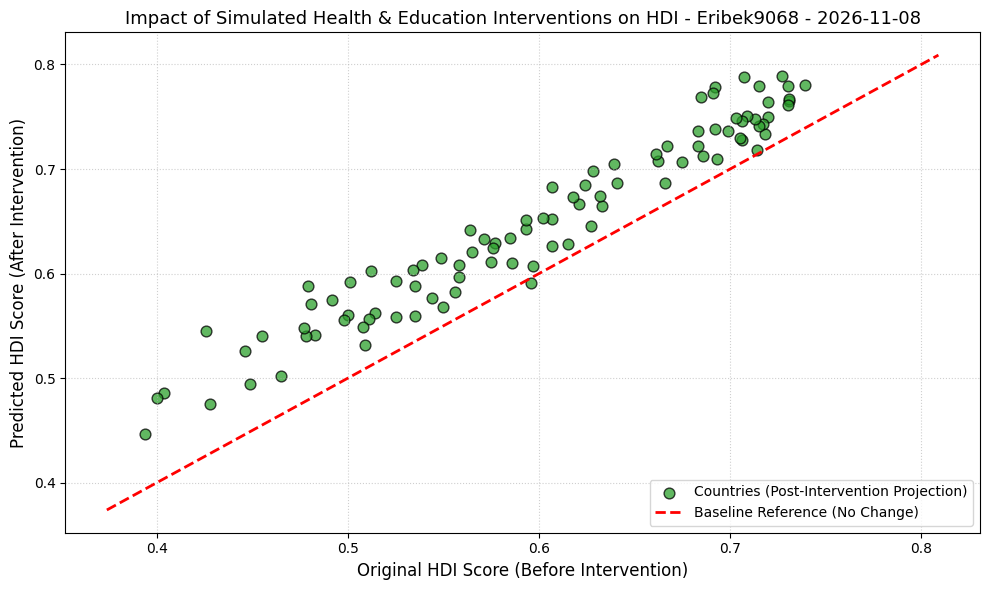

In [4]:
import matplotlib.pyplot as plt

display(Markdown(
    f"### Step 10: Scatter Plot of HDI Before and After Simulated Interventions - {student_id} - {todays_date}"
))

plt.figure(figsize=(10, 6))

# Plot actual original HDI vs. Projected HDI after intervention
plt.scatter(
    intervention_df[hdi_col],
    intervention_df['Predicted HDI after intervention'],
    color='#2ca02c',
    alpha=0.75,
    edgecolors='black',
    s=60,
    label='Countries (Post-Intervention Projection)'
)

# Plot a 45-degree reference line representing "No Change" (Before == After)
min_val = min(intervention_df[hdi_col].min(), intervention_df['Predicted HDI after intervention'].min()) - 0.02
max_val = max(intervention_df[hdi_col].max(), intervention_df['Predicted HDI after intervention'].max()) + 0.02
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Baseline Reference (No Change)')

plt.xlabel('Original HDI Score (Before Intervention)', fontsize=12)
plt.ylabel('Predicted HDI Score (After Intervention)', fontsize=12)
plt.title(f'Impact of Simulated Health & Education Interventions on HDI - {student_id} - {todays_date}', fontsize=13)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
